In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('EV_IoT_Telemetry_15000.csv')

In [3]:
# Create a copy for data cleaning
df_clean = df.copy()

# Check dataset dimensions
print("Number of rows and columns:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Display first 5 rows
print("\nFirst 5 observations:")
display(df.head())

Number of rows and columns: (15000, 24)

Column names:
['Timestamp', 'Vehicle_ID', 'Vehicle_Model', 'City', 'Operating_Mode', 'Vehicle_Speed_kmh', 'Distance_Since_Last_Record_km', 'Odometer_km', 'Ambient_Temperature_C', 'Ambient_Humidity_pct', 'Battery_SOC_pct', 'Battery_SOH_pct', 'Charge_Cycles', 'Battery_Pack_Voltage_V', 'Battery_Pack_Current_A', 'Battery_Temperature_C', 'Motor_RPM', 'Motor_Torque_Nm', 'Motor_Power_kW', 'Motor_Temperature_C', 'Tire_Pressure_psi', 'Tire_Temperature_C', 'Battery_Power_kW', 'Component_Health_Score']

Data types:
Timestamp                         object
Vehicle_ID                        object
Vehicle_Model                     object
City                              object
Operating_Mode                    object
Vehicle_Speed_kmh                float64
Distance_Since_Last_Record_km    float64
Odometer_km                      float64
Ambient_Temperature_C            float64
Ambient_Humidity_pct             float64
Battery_SOC_pct                  float6

,Timestamp,Vehicle_ID,Vehicle_Model,City,Operating_Mode,Vehicle_Speed_kmh,Distance_Since_Last_Record_km,Odometer_km,Ambient_Temperature_C,Ambient_Humidity_pct,...,Battery_Pack_Current_A,Battery_Temperature_C,Motor_RPM,Motor_Torque_Nm,Motor_Power_kW,Motor_Temperature_C,Tire_Pressure_psi,Tire_Temperature_C,Battery_Power_kW,Component_Health_Score
0,01/01/2025 00:00:00,EV_001,Compact,Pune,Idle,0.0,0.0,77040.96,19.48,63.79,...,4.30,22.36,0.0,0.0,0.0,35.32,33.10,18.89,0.96,0.8598
1,01/01/2025 00:00:00,EV_002,Sedan,Hyderabad,Idle,0.0,0.0,77329.26,24.22,70.94,...,2.22,29.06,0.0,0.0,0.0,33.46,35.70,28.27,0.63,0.9113
2,01/01/2025 00:00:00,EV_003,SUV,Mumbai,Idle,0.0,0.0,54060.45,27.48,57.42,...,1.77,30.55,0.0,0.0,0.0,41.69,33.60,28.49,1.31,0.9207
3,01/01/2025 00:00:00,EV_004,Compact,Pune,Charging,0.0,0.0,70126.55,20.64,78.29,...,-46.24,25.02,0.0,0.0,0.0,32.39,33.84,23.86,-16.79,0.9215
4,01/01/2025 00:00:00,EV_005,Sedan,Hyderabad,Idle,0.0,0.0,74408.05,21.51,63.48,...,4.88,29.40,0.0,0.0,0.0,35.63,34.25,24.87,0.95,0.9212


Total missing values: 275
Rows containing at least one missing value: 275

Missing values by column:
Vehicle_Speed_kmh         25
Ambient_Temperature_C     25
Ambient_Humidity_pct      25
Battery_SOC_pct           25
Battery_Pack_Current_A    25
Battery_Temperature_C     25
Motor_RPM                 25
Motor_Temperature_C       25
Tire_Pressure_psi         25
Battery_Power_kW          25
Component_Health_Score    25
dtype: int64


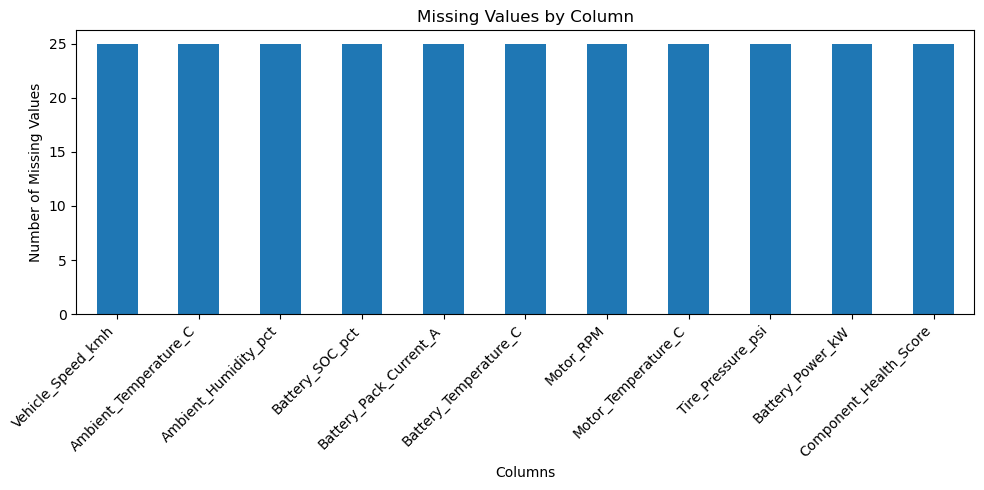

In [4]:
import matplotlib.pyplot as plt

# Count missing values in each column
missing_values = df.isnull().sum()

# Display only columns containing missing values
missing_summary = missing_values[missing_values > 0].sort_values(ascending=False)

print("Total missing values:", df.isnull().sum().sum())
print("Rows containing at least one missing value:", df.isnull().any(axis=1).sum())

if missing_summary.empty:
    print("\nNo missing values found.")
else:
    print("\nMissing values by column:")
    print(missing_summary)

    # Visualize missing values
    missing_summary.plot(kind="bar", figsize=(10, 5))
    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [5]:
# Create a separate copy for cleaning
df_clean = df.copy()

# Select numerical columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Fill missing numerical values with their respective column medians
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Verify the treatment
print("Missing values before treatment:", df.isnull().sum().sum())
print("Missing values after treatment:", df_clean.isnull().sum().sum())
print("Dataset shape after treatment:", df_clean.shape)

Missing values before treatment: 275
Missing values after treatment: 0
Dataset shape after treatment: (15000, 24)


In [6]:
# Count duplicate rows before removal
duplicates_before = df_clean.duplicated().sum()

print("Duplicate rows before removal:", duplicates_before)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Verify the result
duplicates_after = df_clean.duplicated().sum()

print("Duplicate rows after removal:", duplicates_after)
print("Rows removed:", duplicates_before - duplicates_after)
print("Dataset shape after treatment:", df_clean.shape)

Duplicate rows before removal: 25
Duplicate rows after removal: 0
Rows removed: 25
Dataset shape after treatment: (14975, 24)


In [7]:
# Check for physically implausible observations

invalid_checks = {
    "Vehicle_Speed_kmh":
        (df_clean["Vehicle_Speed_kmh"] < 0) |
        (df_clean["Vehicle_Speed_kmh"] > 180),

    "Distance_Since_Last_Record_km":
        df_clean["Distance_Since_Last_Record_km"] < 0,

    "Odometer_km":
        df_clean["Odometer_km"] < 0,

    "Ambient_Temperature_C":
        (df_clean["Ambient_Temperature_C"] < -50) |
        (df_clean["Ambient_Temperature_C"] > 70),

    "Ambient_Humidity_pct":
        (df_clean["Ambient_Humidity_pct"] < 0) |
        (df_clean["Ambient_Humidity_pct"] > 100),

    "Battery_SOC_pct":
        (df_clean["Battery_SOC_pct"] < 0) |
        (df_clean["Battery_SOC_pct"] > 100),

    "Battery_SOH_pct":
        (df_clean["Battery_SOH_pct"] < 0) |
        (df_clean["Battery_SOH_pct"] > 100),

    "Charge_Cycles":
        df_clean["Charge_Cycles"] < 0,

    "Battery_Pack_Voltage_V":
        df_clean["Battery_Pack_Voltage_V"] <= 0,

    "Battery_Temperature_C":
        (df_clean["Battery_Temperature_C"] < -40) |
        (df_clean["Battery_Temperature_C"] > 120),

    "Motor_RPM":
        df_clean["Motor_RPM"] < 0,

    "Motor_Temperature_C":
        (df_clean["Motor_Temperature_C"] < -40) |
        (df_clean["Motor_Temperature_C"] > 200),

    "Tire_Pressure_psi":
        (df_clean["Tire_Pressure_psi"] <= 0) |
        (df_clean["Tire_Pressure_psi"] > 100),

    "Tire_Temperature_C":
        (df_clean["Tire_Temperature_C"] < -50) |
        (df_clean["Tire_Temperature_C"] > 150),

    "Component_Health_Score":
        (df_clean["Component_Health_Score"] < 0) |
        (df_clean["Component_Health_Score"] > 1)
}

# Count invalid observations in each checked column
invalid_counts = {
    column: int(mask.sum())
    for column, mask in invalid_checks.items()
}

print("Invalid observations by column:")

found_invalid = False

for column, count in invalid_counts.items():
    if count > 0:
        print(f"{column}: {count}")
        found_invalid = True

if not found_invalid:
    print("No invalid observations found in the checked columns.")

Invalid observations by column:
Vehicle_Speed_kmh: 4
Ambient_Humidity_pct: 4
Battery_SOC_pct: 4
Battery_SOH_pct: 3
Battery_Pack_Voltage_V: 1
Motor_RPM: 3
Tire_Pressure_psi: 1
Component_Health_Score: 2


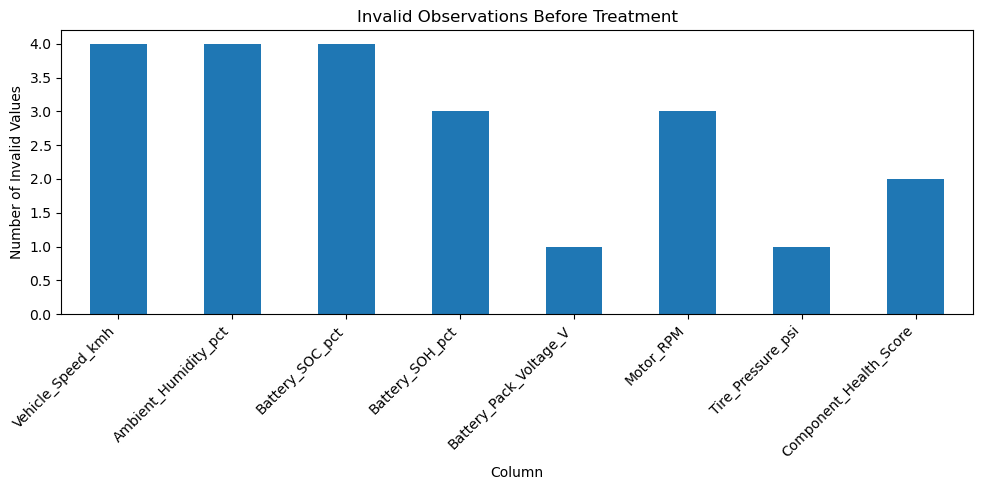

Invalid values treated: 22
Missing values after treatment: 0
Dataset shape: (14975, 24)


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Visualize invalid observations before treatment
invalid_series = pd.Series(invalid_counts)
invalid_series = invalid_series[invalid_series > 0]

invalid_series.plot(kind="bar", figsize=(10, 5))
plt.title("Invalid Observations Before Treatment")
plt.xlabel("Column")
plt.ylabel("Number of Invalid Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Replace invalid values with NaN
for column, mask in invalid_checks.items():
    df_clean.loc[mask, column] = np.nan

# Fill the resulting NaN values with the respective column median
for column in invalid_checks:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# Verify treatment
print("Invalid values treated:", sum(invalid_counts.values()))
print("Missing values after treatment:", df_clean.isnull().sum().sum())
print("Dataset shape:", df_clean.shape)

In [9]:
# Prepare timestamp values
timestamp_text = df_clean["Timestamp"].astype("string").str.strip()

# Detect whether dates use DD/MM/YYYY or MM/DD/YYYY
date_parts = timestamp_text.str.extract(
    r"^(\d{1,2})/(\d{1,2})/(\d{4})"
)

first_part = pd.to_numeric(date_parts[0], errors="coerce")
second_part = pd.to_numeric(date_parts[1], errors="coerce")

if (first_part > 12).any():
    dayfirst = True
elif (second_part > 12).any():
    dayfirst = False
else:
    dayfirst = True  # Assumption when the date order is ambiguous

# Convert to datetime
df_clean["Timestamp"] = pd.to_datetime(
    timestamp_text,
    dayfirst=dayfirst,
    errors="coerce"
)

# Verify the conversion
print("Detected date format:",
      "DD/MM/YYYY" if dayfirst else "MM/DD/YYYY")
print("Timestamp data type:", df_clean["Timestamp"].dtype)
print("Failed conversions:", df_clean["Timestamp"].isna().sum())
print("\nFirst 5 timestamps:")
print(df_clean["Timestamp"].head())

Detected date format: MM/DD/YYYY
Timestamp data type: datetime64[ns]
Failed conversions: 4

First 5 timestamps:
0   2025-01-01
1   2025-01-01
2   2025-01-01
3   2025-01-01
4   2025-01-01
Name: Timestamp, dtype: datetime64[ns]


In [10]:
# Find rows where timestamp conversion failed
invalid_timestamp_indices = df_clean.index[
    df_clean["Timestamp"].isna()
]

# Display the original timestamp values
print("Number of invalid timestamps:", len(invalid_timestamp_indices))

print("\nOriginal timestamp values:")
print(
    df.loc[
        invalid_timestamp_indices,
        ["Timestamp", "Vehicle_ID", "City"]
    ]
)

Number of invalid timestamps: 4

Original timestamp values:
              Timestamp Vehicle_ID       City
4216   2025-13-40 99:99     EV_015     Mumbai
4366    not_a_timestamp     EV_005  Hyderabad
13644   not_a_timestamp     EV_010       Pune
14983  2025-13-40 99:99     EV_004       Pune


In [11]:
# Remove rows with invalid timestamps
df_clean = df_clean.drop(index=invalid_timestamp_indices)

# Verify the result
print("Invalid timestamps remaining:",
      df_clean["Timestamp"].isna().sum())

print("Dataset shape after timestamp treatment:",
      df_clean.shape)

print("Timestamp data type:",
      df_clean["Timestamp"].dtype)

Invalid timestamps remaining: 0
Dataset shape after timestamp treatment: (14971, 24)
Timestamp data type: datetime64[ns]


In [12]:
# Select categorical columns
categorical_cols = [
    "Vehicle_ID",
    "Vehicle_Model",
    "City",
    "Operating_Mode"
]

# Inspect unique values and their frequencies
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", df_clean[col].nunique())
    print(df_clean[col].value_counts(dropna=False))


--- Vehicle_ID ---
Unique values: 20
Vehicle_ID
EV_014    750
EV_013    750
EV_008    750
EV_001    749
EV_010    749
EV_018    749
EV_016    749
EV_012    749
EV_002    749
EV_011    749
EV_009    749
EV_005    749
EV_004    749
EV_003    749
EV_007    748
EV_019    748
EV_020    748
EV_017    747
EV_006    746
EV_015    745
Name: count, dtype: int64

--- Vehicle_Model ---
Unique values: 3
Vehicle_Model
Compact    5242
Sedan      5242
SUV        4487
Name: count, dtype: int64

--- City ---
Unique values: 3
City
Pune         5242
Hyderabad    5242
Mumbai       4487
Name: count, dtype: int64

--- Operating_Mode ---
Unique values: 11
Operating_Mode
Driving      7952
Idle         4140
Charging     2871
idle            1
IDLE            1
drive           1
CHARGING        1
DRIVING         1
Charging        1
charging        1
driving         1
Name: count, dtype: int64


In [13]:
# Clean Vehicle_ID
df_clean["Vehicle_ID"] = (
    df_clean["Vehicle_ID"].astype("string").str.strip().str.upper()
)

# Standardize Vehicle_Model labels
model_map = {
    "compact": "Compact",
    "sedan": "Sedan",
    "suv": "SUV"
}

df_clean["Vehicle_Model"] = (
    df_clean["Vehicle_Model"]
    .astype("string").str.strip().str.lower()
    .map(model_map)
)

# Standardize City labels
df_clean["City"] = (
    df_clean["City"].astype("string").str.strip().str.title()
)

# Standardize Operating_Mode labels
mode_map = {
    "driving": "Driving",
    "drive": "Driving",
    "idle": "Idle",
    "charging": "Charging"
}

df_clean["Operating_Mode"] = (
    df_clean["Operating_Mode"]
    .astype("string").str.strip().str.lower()
    .map(mode_map)
)

# Verify the cleaned categories
for col in ["Vehicle_ID", "Vehicle_Model", "City", "Operating_Mode"]:
    print(f"\n{col}: {df_clean[col].nunique()} unique values")
    print(df_clean[col].value_counts(dropna=False))

print("\nMissing values after categorical cleaning:",
      df_clean[["Vehicle_ID", "Vehicle_Model", "City",
                 "Operating_Mode"]].isna().sum().sum())

print("Dataset shape:", df_clean.shape)


Vehicle_ID: 20 unique values
Vehicle_ID
EV_014    750
EV_013    750
EV_008    750
EV_001    749
EV_010    749
EV_018    749
EV_016    749
EV_012    749
EV_002    749
EV_011    749
EV_009    749
EV_005    749
EV_004    749
EV_003    749
EV_007    748
EV_019    748
EV_020    748
EV_017    747
EV_006    746
EV_015    745
Name: count, dtype: Int64

Vehicle_Model: 3 unique values
Vehicle_Model
Compact    5242
Sedan      5242
SUV        4487
Name: count, dtype: int64

City: 3 unique values
City
Pune         5242
Hyderabad    5242
Mumbai       4487
Name: count, dtype: Int64

Operating_Mode: 3 unique values
Operating_Mode
Driving     7955
Idle        4142
Charging    2874
Name: count, dtype: int64

Missing values after categorical cleaning: 0
Dataset shape: (14971, 24)


Outliers detected by column:
Battery_SOC_pct                  391
Battery_Pack_Voltage_V           387
Battery_Power_kW                 307
Battery_Pack_Current_A           296
Motor_Power_kW                   270
Motor_Temperature_C              201
Ambient_Humidity_pct              98
Battery_Temperature_C             51
Ambient_Temperature_C             12
Distance_Since_Last_Record_km      5
Component_Health_Score             5
Tire_Pressure_psi                  2
Tire_Temperature_C                 2
dtype: int64

Total outlier values detected: 2027


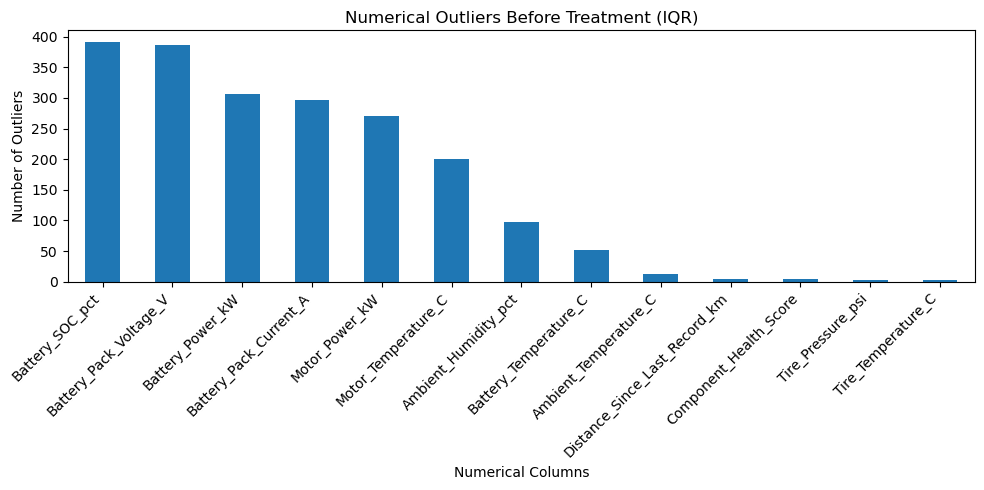


Outliers remaining after capping: 0
Missing values: 0
Final dataset shape: (14971, 24)


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Select numerical columns
numeric_cols = df_clean.select_dtypes(include="number").columns

outlier_counts = {}
iqr_bounds = {}

# Step 1: Detect outliers using IQR
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    iqr_bounds[col] = (lower_bound, upper_bound)

    outlier_counts[col] = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

# Display outlier counts
outlier_summary = pd.Series(outlier_counts)
outlier_summary = outlier_summary[outlier_summary > 0]
outlier_summary = outlier_summary.sort_values(ascending=False)

print("Outliers detected by column:")
print(outlier_summary)

print("\nTotal outlier values detected:", int(outlier_summary.sum()))

# Step 2: Visualize detected outliers
if not outlier_summary.empty:
    outlier_summary.plot(kind="bar", figsize=(10, 5))
    plt.title("Numerical Outliers Before Treatment (IQR)")
    plt.xlabel("Numerical Columns")
    plt.ylabel("Number of Outliers")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Step 3: Treat outliers using IQR capping
for col, (lower_bound, upper_bound) in iqr_bounds.items():
    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

# Step 4: Verify treatment
remaining_outliers = 0

for col, (lower_bound, upper_bound) in iqr_bounds.items():
    remaining_outliers += (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

print("\nOutliers remaining after capping:", int(remaining_outliers))
print("Missing values:", int(df_clean.isnull().sum().sum()))
print("Final dataset shape:", df_clean.shape)

In [25]:
# Columns selected for IQR capping ONLY
columns_to_cap = [
    "Ambient_Humidity_pct",
    "Battery_Temperature_C",
    "Ambient_Temperature_C",
    "Distance_Since_Last_Record_km",
    "Component_Health_Score",
    "Tire_Pressure_psi",
    "Tire_Temperature_C"
]

# Count and cap outliers only in the selected columns
for col in columns_to_cap:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers_before = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    # Cap only the current selected column
    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    print(f"{col}: {outliers_before} outliers capped")

print("\nDataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

Ambient_Humidity_pct: 0 outliers capped
Battery_Temperature_C: 0 outliers capped
Ambient_Temperature_C: 0 outliers capped
Distance_Since_Last_Record_km: 0 outliers capped
Component_Health_Score: 0 outliers capped
Tire_Pressure_psi: 0 outliers capped
Tire_Temperature_C: 0 outliers capped

Dataset shape: (14971, 24)
Missing values: 0


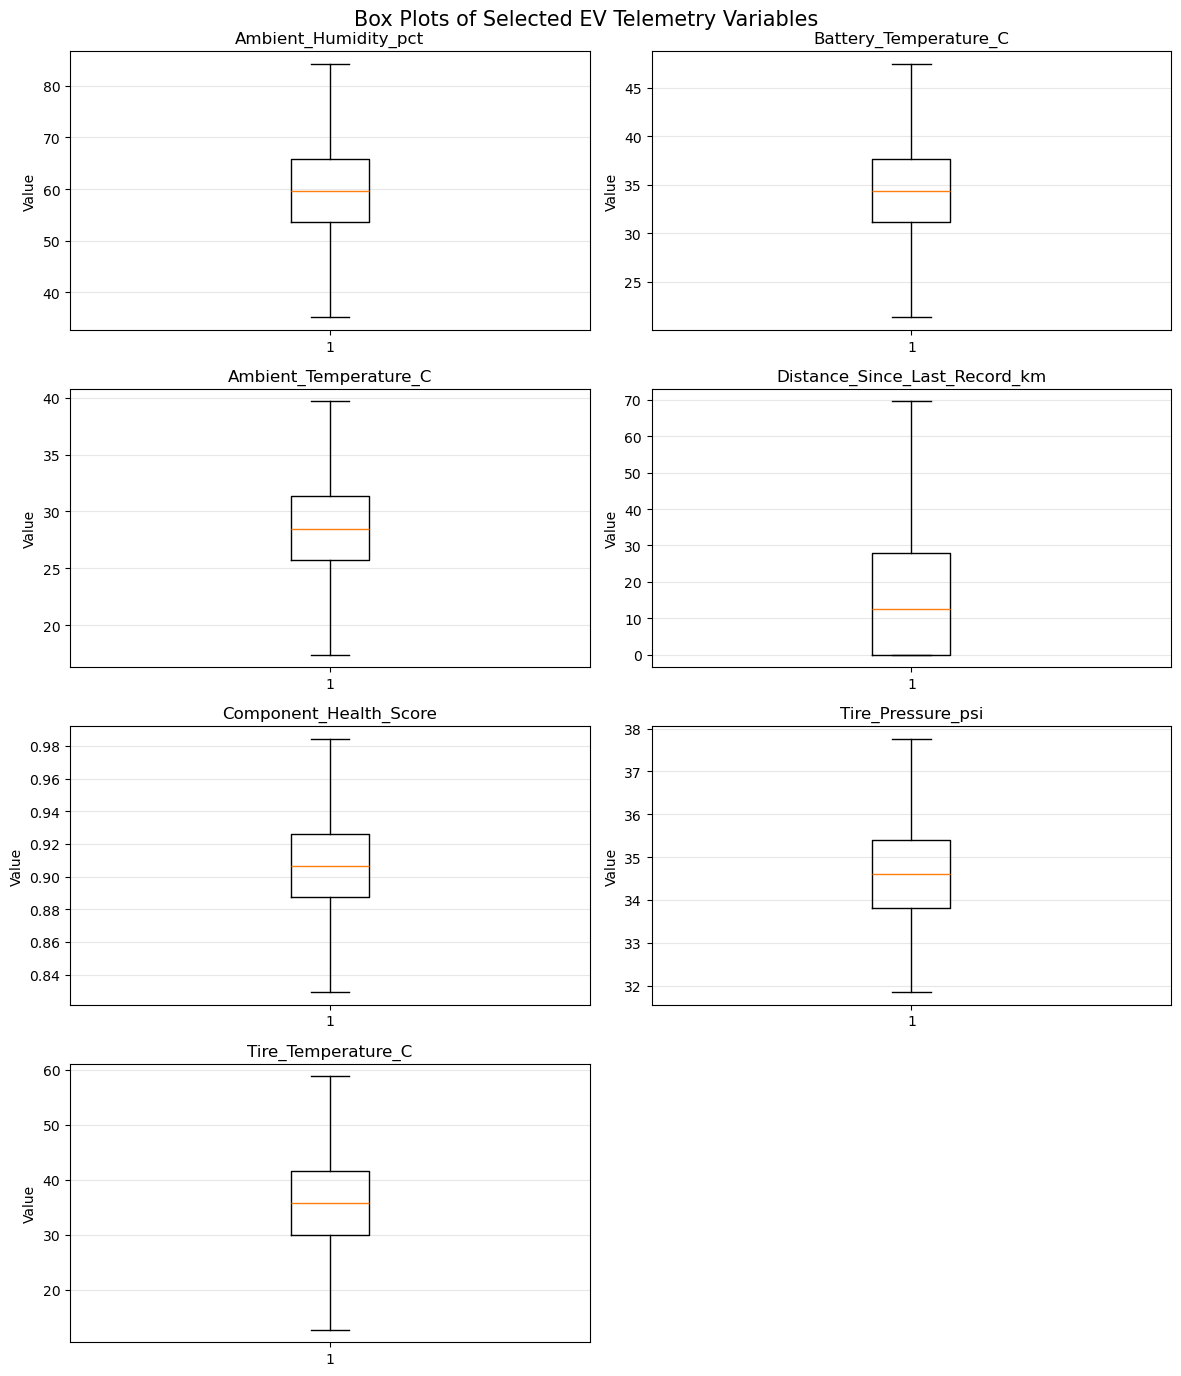

In [26]:
import matplotlib.pyplot as plt

# Columns to visualize
columns_to_plot = [
    "Ambient_Humidity_pct",
    "Battery_Temperature_C",
    "Ambient_Temperature_C",
    "Distance_Since_Last_Record_km",
    "Component_Health_Score",
    "Tire_Pressure_psi",
    "Tire_Temperature_C"
]

# Create separate box plots
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
axes = axes.flatten()

for i, col in enumerate(columns_to_plot):
    axes[i].boxplot(df_clean[col].dropna(), vert=True)
    axes[i].set_title(col)
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", alpha=0.3)

# Hide the unused subplot
axes[-1].set_visible(False)

plt.suptitle("Box Plots of Selected EV Telemetry Variables", fontsize=15)
plt.tight_layout()
plt.show()

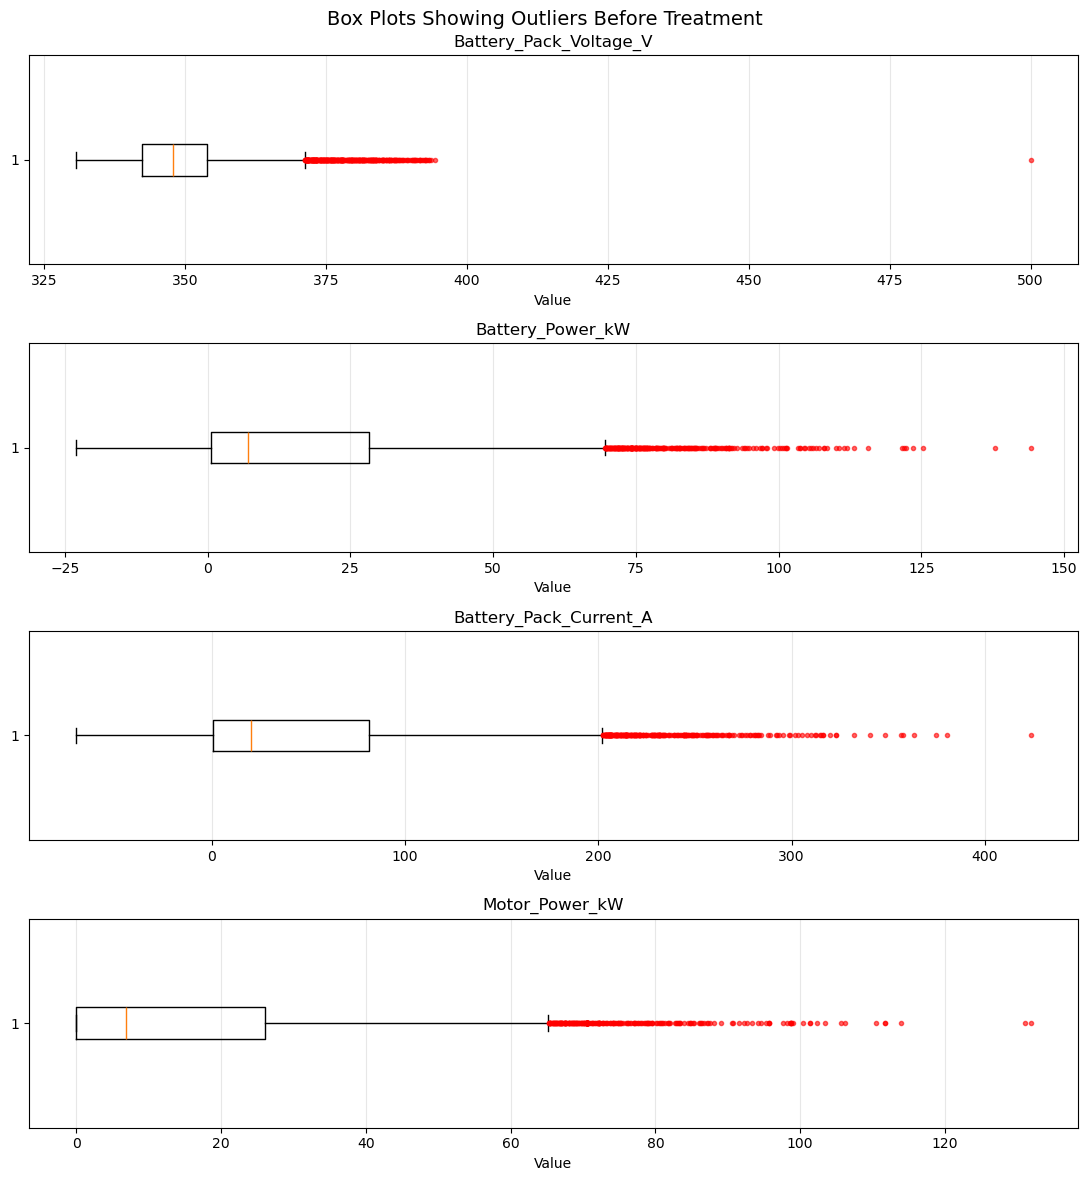

In [27]:
import matplotlib.pyplot as plt

# Columns whose outliers we want to retain
columns_to_plot = [
    "Battery_Pack_Voltage_V",
    "Battery_Power_kW",
    "Battery_Pack_Current_A",
    "Motor_Power_kW"
]

# Create separate box plots
fig, axes = plt.subplots(4, 1, figsize=(11, 12))

for ax, col in zip(axes, columns_to_plot):
    ax.boxplot(
        df_clean[col].dropna(),
        vert=False,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "red",
            "markeredgecolor": "red",
            "alpha": 0.6
        }
    )

    ax.set_title(col)
    ax.set_xlabel("Value")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle("Box Plots Showing Outliers Before Treatment", fontsize=14)
plt.tight_layout()
plt.show()

In [28]:
# Calculate estimated power from related sensor readings
battery_power_est = (
    df_clean["Battery_Pack_Voltage_V"]
    * df_clean["Battery_Pack_Current_A"]
    / 1000
)

motor_power_est = (
    df_clean["Motor_Torque_Nm"]
    * df_clean["Motor_RPM"]
    / 9550
)

# Compare estimated and recorded power
battery_check = pd.DataFrame({
    "Vehicle_ID": df_clean["Vehicle_ID"],
    "Battery_Power_Recorded": df_clean["Battery_Power_kW"],
    "Battery_Power_Estimated": battery_power_est
})

battery_check["Absolute_Difference"] = (
    battery_check["Battery_Power_Recorded"]
    - battery_check["Battery_Power_Estimated"]
).abs()

motor_check = pd.DataFrame({
    "Vehicle_ID": df_clean["Vehicle_ID"],
    "Motor_Power_Recorded": df_clean["Motor_Power_kW"],
    "Motor_Power_Estimated": motor_power_est
})

motor_check["Absolute_Difference"] = (
    motor_check["Motor_Power_Recorded"]
    - motor_check["Motor_Power_Estimated"]
).abs()

print("Battery power: 10 largest differences")
display(battery_check.sort_values(
    "Absolute_Difference", ascending=False
).head(10))

print("Motor power: 10 largest differences")
display(motor_check.sort_values(
    "Absolute_Difference", ascending=False
).head(10))

Battery power: 10 largest differences


,Vehicle_ID,Battery_Power_Recorded,Battery_Power_Estimated,Absolute_Difference
9644,EV_006,7.00,92.349839,85.349839
889,EV_008,7.00,88.559243,81.559243
13422,EV_008,63.09,6.816421,56.273579
14446,EV_011,7.00,61.412630,54.412630
13476,EV_002,7.00,59.482269,52.482269
14043,EV_008,7.00,50.750410,43.750410
9397,EV_019,7.00,49.400623,42.400623
9546,EV_009,44.46,6.766297,37.693703
7421,EV_002,7.00,41.545746,34.545746
14964,EV_005,7.00,-19.809880,26.809880


Motor power: 10 largest differences


,Vehicle_ID,Motor_Power_Recorded,Motor_Power_Estimated,Absolute_Difference
13705,EV_011,76.04,19.923013,56.116987
10301,EV_003,59.58,19.641953,39.938047
12072,EV_018,43.76,18.479729,25.280271
10392,EV_014,35.98,13.209845,22.770155
4434,EV_014,34.80,12.938279,21.861721
1342,EV_020,34.94,13.492804,21.447196
3573,EV_012,32.47,13.538382,18.931618
8680,EV_003,32.88,14.199254,18.680746
2353,EV_010,28.52,12.123584,16.396416
4154,EV_013,26.37,11.588049,14.781951


In [29]:
# Calculate estimated power
battery_estimated = (
    df_clean["Battery_Pack_Voltage_V"]
    * df_clean["Battery_Pack_Current_A"]
    / 1000
)

motor_estimated = (
    df_clean["Motor_Torque_Nm"]
    * df_clean["Motor_RPM"]
    / 9550
)

# Calculate absolute differences
battery_diff = (
    df_clean["Battery_Power_kW"] - battery_estimated
).abs()

motor_diff = (
    df_clean["Motor_Power_kW"] - motor_estimated
).abs()

# Flag records for review; do not change any data
threshold = 10

print(
    "Battery power records flagged:",
    (battery_diff > threshold).sum()
)

print(
    "Motor power records flagged:",
    (motor_diff > threshold).sum()
)

print("\nDataset shape:", df_clean.shape)

Battery power records flagged: 31
Motor power records flagged: 11

Dataset shape: (14971, 24)


In [30]:
# Identify records with potential power inconsistencies
battery_flag = battery_diff > threshold
motor_flag = motor_diff > threshold

flagged_records = df_clean.loc[
    battery_flag | motor_flag,
    [
        "Timestamp",
        "Vehicle_ID",
        "Operating_Mode",
        "Battery_Pack_Voltage_V",
        "Battery_Pack_Current_A",
        "Battery_Power_kW",
        "Motor_Torque_Nm",
        "Motor_RPM",
        "Motor_Power_kW"
    ]
].copy()

# Add flags and differences for investigation
flagged_records["Battery_Power_Difference_kW"] = battery_diff.loc[
    flagged_records.index
]
flagged_records["Motor_Power_Difference_kW"] = motor_diff.loc[
    flagged_records.index
]

flagged_records["Battery_Power_Flag"] = battery_flag.loc[
    flagged_records.index
]
flagged_records["Motor_Power_Flag"] = motor_flag.loc[
    flagged_records.index
]

print("Unique records flagged:", len(flagged_records))
display(flagged_records.head(10))

print("\nDataset shape remains:", df_clean.shape)

Unique records flagged: 42


,Timestamp,Vehicle_ID,Operating_Mode,Battery_Pack_Voltage_V,Battery_Pack_Current_A,Battery_Power_kW,Motor_Torque_Nm,Motor_RPM,Motor_Power_kW,Battery_Power_Difference_kW,Motor_Power_Difference_kW,Battery_Power_Flag,Motor_Power_Flag
397,2025-01-03 09:00:00,EV_017,Driving,370.68,20.13,32.95,70.55,4290.2,31.69,25.488212,0.003572,True,False
814,2025-01-06 00:00:00,EV_012,Charging,358.59,-33.38,7.00,0.00,0.0,0.00,18.969734,0.000000,True,False
889,2025-01-06 12:00:00,EV_008,Driving,356.06,248.72,7.00,115.95,6993.5,84.91,81.559243,0.000610,True,False
1342,2025-01-09 06:00:00,EV_020,Driving,345.99,113.97,39.47,71.05,1813.6,34.94,0.037520,21.447196,False,True
2119,2025-01-14 03:00:00,EV_016,Charging,340.24,20.13,-13.36,0.00,0.0,0.00,20.209031,0.000000,True,False
2353,2025-01-15 15:00:00,EV_010,Driving,350.47,81.72,29.22,63.84,1813.6,28.52,0.579592,16.396416,False,True
2465,2025-01-16 09:00:00,EV_002,Driving,341.44,66.01,7.00,56.21,3616.5,21.28,15.538454,0.006227,True,False
3573,2025-01-23 06:00:00,EV_012,Driving,356.84,94.18,34.93,71.29,1813.6,32.47,1.322809,18.931618,False,True
4154,2025-01-26 21:00:00,EV_013,Driving,346.38,80.35,28.69,61.02,1813.6,26.37,0.858367,14.781951,False,True
4434,2025-01-28 15:00:00,EV_014,Driving,360.82,110.92,39.96,68.13,1813.6,34.80,0.062154,21.861721,False,True



Dataset shape remains: (14971, 24)


In [31]:
# Remove the 42 records with power inconsistencies
df_clean = df_clean.drop(index=flagged_records.index)

# Verify the result
print("Records removed:", len(flagged_records))
print("Final dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

Records removed: 42
Final dataset shape: (14929, 24)
Missing values: 0
Duplicate rows: 0


In [32]:
# Descriptive statistics for numerical columns
descriptive_stats = df_clean.describe().T

# Round values for readability
descriptive_stats = descriptive_stats.round(2)

print("Descriptive Statistics:")
display(descriptive_stats)

print("\nDataset shape:", df_clean.shape)

Descriptive Statistics:


,count,mean,min,25%,50%,75%,max,std
Timestamp,14929,2025-02-16 18:44:04.838904064,2025-01-01 00:00:00,2025-01-24 09:00:00,2025-02-16 18:00:00,2025-03-12 06:00:00,2025-04-04 15:00:00,NaN
Vehicle_Speed_kmh,14929.0,27.123872,0.0,0.0,24.77,52.1,108.0,28.266196
Distance_Since_Last_Record_km,14929.0,14.944072,0.0,0.0,12.58,27.8,69.5625,16.207191
Odometer_km,14929.0,58039.984993,17134.58,37659.09,61086.22,79295.79,90508.81,21845.099963
Ambient_Temperature_C,14929.0,28.477587,17.395,25.75,28.49,31.31,39.675,3.973326
Ambient_Humidity_pct,14929.0,59.701962,35.18,53.59,59.67,65.84,84.22,8.988149
Battery_SOC_pct,14929.0,35.548467,15.0,27.56,34.57,42.01,63.65,10.648043
Battery_SOH_pct,14929.0,93.303351,88.62,91.12,92.62,95.4,98.69,2.818895
Charge_Cycles,14929.0,186.09667,66.2,134.48,173.82,242.0,334.42,75.030379
Battery_Pack_Voltage_V,14929.0,348.845166,330.66,342.25,347.84,353.82,500.0,9.282



Dataset shape: (14929, 24)


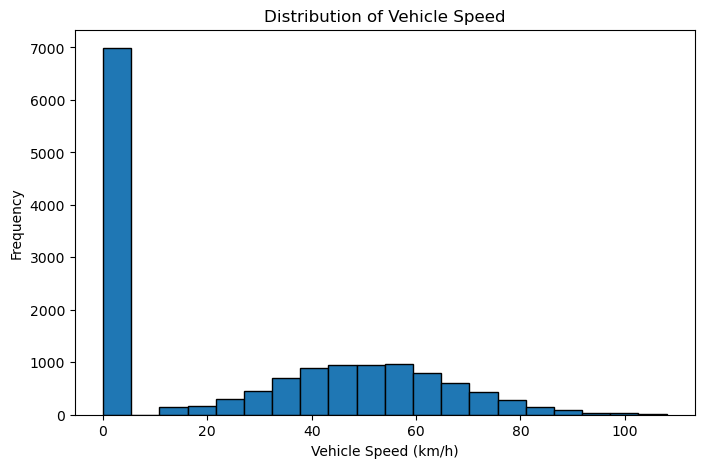

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean["Vehicle_Speed_kmh"], bins=20, edgecolor="black")

plt.title("Distribution of Vehicle Speed")
plt.xlabel("Vehicle Speed (km/h)")
plt.ylabel("Frequency")

plt.show()

Operating_Mode
Driving     7926
Idle        4142
Charging    2861
Name: count, dtype: int64


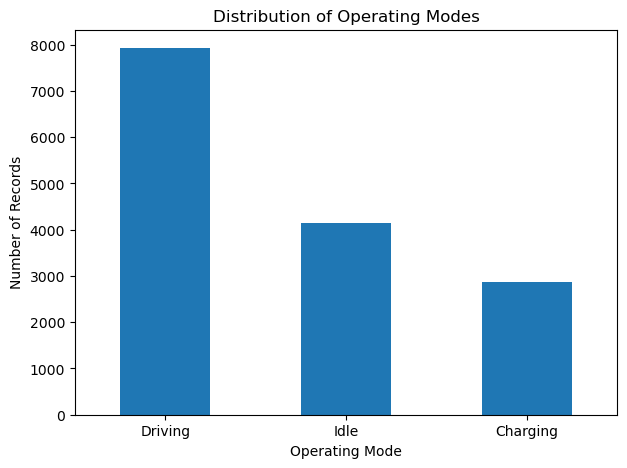

In [34]:
# Count records in each operating mode
mode_counts = df_clean["Operating_Mode"].value_counts()

print(mode_counts)

# Bar chart
mode_counts.plot(
    kind="bar",
    figsize=(7, 5),
    title="Distribution of Operating Modes",
    xlabel="Operating Mode",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)
plt.show()

Vehicle_Model
Compact    5232
Sedan      5221
SUV        4476
Name: count, dtype: int64


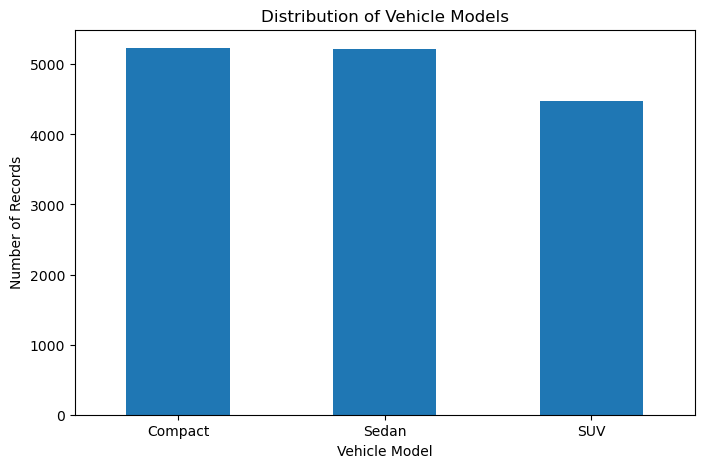

In [35]:
# Count records for each vehicle model
model_counts = df_clean["Vehicle_Model"].value_counts()

print(model_counts)

# Bar chart
model_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribution of Vehicle Models",
    xlabel="Vehicle Model",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)
plt.show()

City
Pune         5232
Hyderabad    5221
Mumbai       4476
Name: count, dtype: Int64


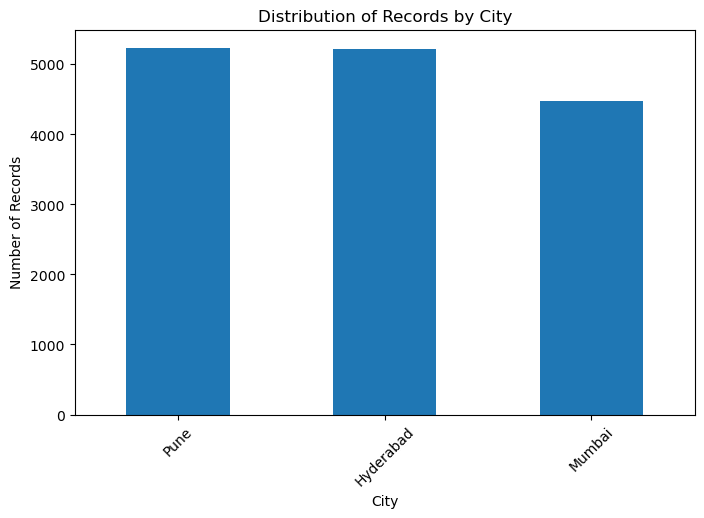

In [36]:
# Count records for each city
city_counts = df_clean["City"].value_counts()

print(city_counts)

# Bar chart
city_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribution of Records by City",
    xlabel="City",
    ylabel="Number of Records"
)

plt.xticks(rotation=45)
plt.show()

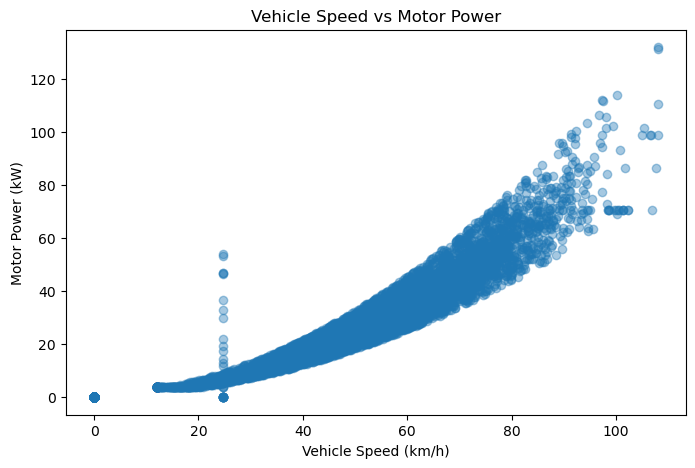

In [37]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Vehicle_Speed_kmh"],
    df_clean["Motor_Power_kW"],
    alpha=0.4
)

plt.title("Vehicle Speed vs Motor Power")
plt.xlabel("Vehicle Speed (km/h)")
plt.ylabel("Motor Power (kW)")

plt.show()

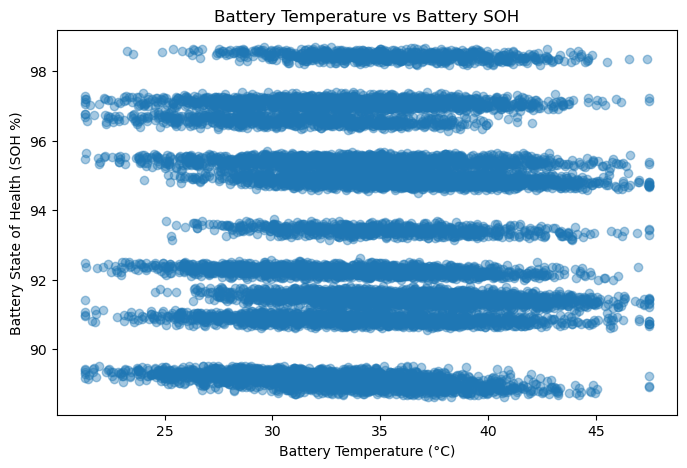

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Battery_Temperature_C"],
    df_clean["Battery_SOH_pct"],
    alpha=0.4
)

plt.title("Battery Temperature vs Battery SOH")
plt.xlabel("Battery Temperature (°C)")
plt.ylabel("Battery State of Health (SOH %)")
plt.show()

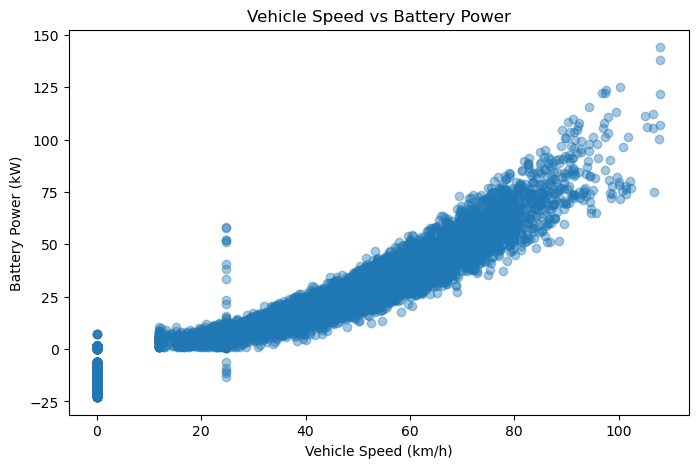

In [39]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Vehicle_Speed_kmh"],
    df_clean["Battery_Power_kW"],
    alpha=0.4
)

plt.title("Vehicle Speed vs Battery Power")
plt.xlabel("Vehicle Speed (km/h)")
plt.ylabel("Battery Power (kW)")

plt.show()

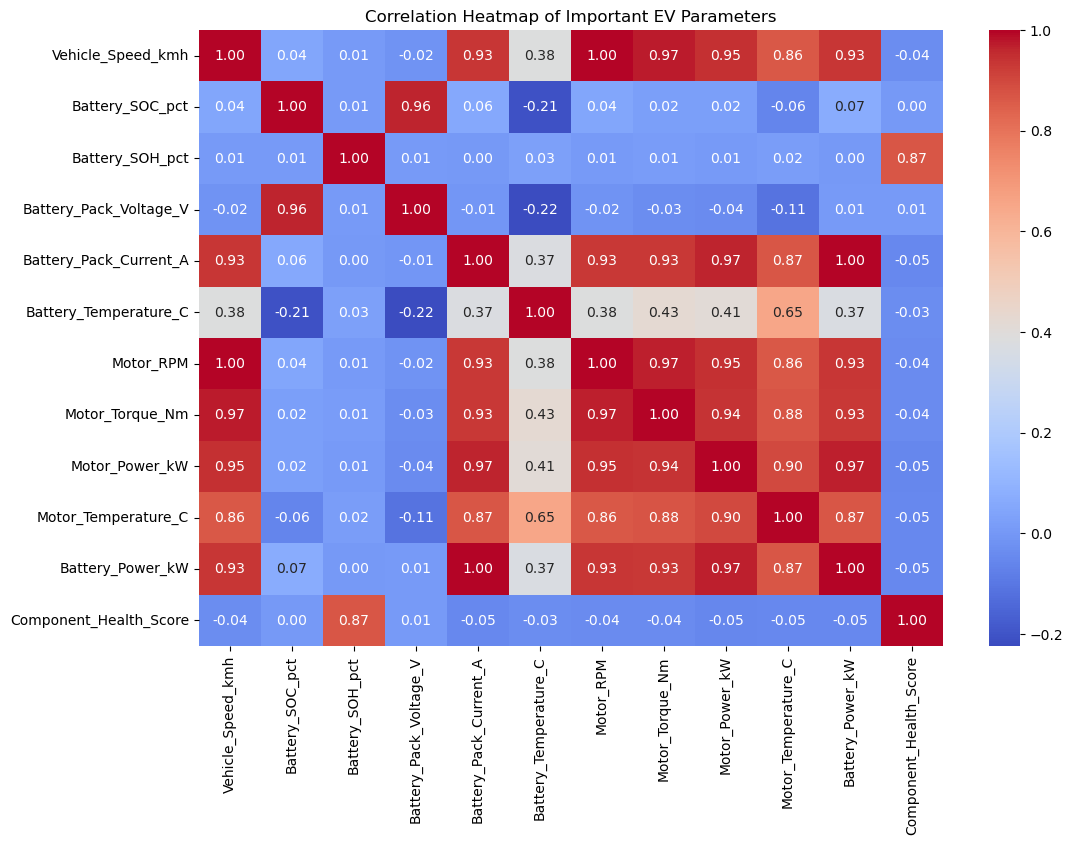

In [42]:
# Select important numerical variables
corr_cols = [
    "Vehicle_Speed_kmh",
    "Battery_SOC_pct",
    "Battery_SOH_pct",
    "Battery_Pack_Voltage_V",
    "Battery_Pack_Current_A",
    "Battery_Temperature_C",
    "Motor_RPM",
    "Motor_Torque_Nm",
    "Motor_Power_kW",
    "Motor_Temperature_C",
    "Battery_Power_kW",
    "Component_Health_Score"
]

# Calculate correlation matrix
corr_matrix = df_clean[corr_cols].corr()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Important EV Parameters")
plt.show()